Dataset:
   Study_Hours  Result
0            1       0
1            2       0
2            3       0
3            4       0
4            5       1
5            6       1
6            7       1
7            8       1
8            9       1
9           10       1

Predicted Classes: [0 1]

Prediction Probabilities:
[[0.80171244 0.19828756]
 [0.05985285 0.94014715]]

Accuracy: 1.0

Confusion Matrix:
[[1 0]
 [0 1]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2


Predicted Result: Pass
Pass Probability: 0.7680717703174468


c:\Users\KHUSHBOO KAUSHIK\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


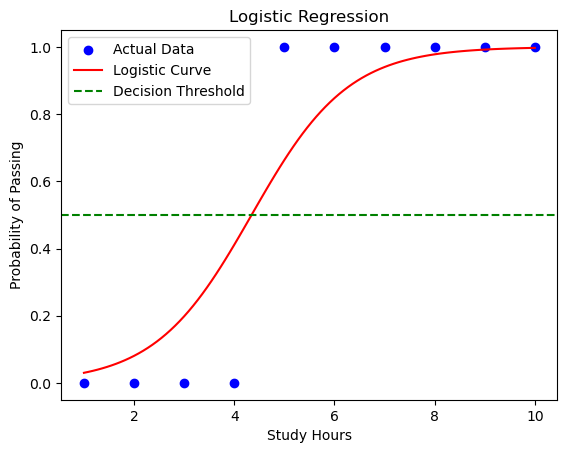

In [1]:
# Practical 3: Logistic Regression

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

# Step 2: Create dataset
data = {
    'Study_Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Result': [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# Step 3: Separate input and output
X = df[['Study_Hours']]
y = df['Result']

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 5: Create Logistic Regression model
model = LogisticRegression()

# Step 6: Train model
model.fit(X_train, y_train)

# Step 7: Predict test data
y_pred = model.predict(X_test)

# Step 8: Calculate probabilities
probabilities = model.predict_proba(X_test)

print("\nPredicted Classes:", y_pred)
print("\nPrediction Probabilities:")
print(probabilities)

# Step 9: Evaluate model
print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Step 10: Predict for a new student
new_student = pd.DataFrame({'Study_Hours': [5.5]})

prediction = model.predict(new_student)
probability = model.predict_proba(new_student)

print("\nPredicted Result:",
      "Pass" if prediction[0] == 1 else "Fail")

print("Pass Probability:", probability[0][1])

# Step 11: Visualize predictions
plt.scatter(X, y, color='blue', label='Actual Data')

x_range = np.linspace(1, 10, 100).reshape(-1, 1)

plt.plot(
    x_range,
    model.predict_proba(x_range)[:, 1],
    color='red',
    label='Logistic Curve'
)

plt.axhline(0.5, color='green', linestyle='--',
            label='Decision Threshold')

plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression")
plt.legend()
plt.show()
